# Final Model Build and Tuning

This notebook builds several models using cross validation and selects the one with the best average r-squared value
Notable steps:
- read in multi-stint dataset
- add features on a per-stint basis to avoid bleed, including lagging and rate features.
- Keep one stint out for final testing; use remaining stints for training and validation
- Identify top features per pre-selected groups using SHAP on XGBRegressor
- Use "Leave One Stint Out" Cross Validation to train 5 separate models and report on mean r-squared, RMSE values
- Build final model and report


## Load Data and add features

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import time

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.feature_selection import RFE
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, mean_absolute_percentage_error
import shap
import matplotlib.pyplot as plt


from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import LeaveOneGroupOut
import joblib


from assign_turns_to_df import assign_turns_to_dataframe
from degradation_components_full import (
    compute_friction_penalty,
    compute_thermal_aging_penalty,
    compute_asymmetric_penalty,
    compute_transient_penalty,
    compute_corner_g_loss_by_turn,
    compute_combined_degradation,
    estimate_per_tire_fx,
    estimate_slip_power
)


g:\My Drive\Georgia Tech\2025 Practicum\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# 1. Load your data
df = pd.read_parquet("parquet_files\\master_12hz_8stints.parquet")

# drop warmup lap and stop at lap 15
laps_to_plot = np.arange(1,16)

df = df[(df["Lap"].isin(laps_to_plot))]

df["LatG"] = df["LatAccel"].abs()
df["LongG"] = df["LongAccel"].abs()

df['source_file'].unique()

array(['porsche992cup_lagunaseca 2025-06-18 11-58-07_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-17 21-37-16_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-17 10-52-45_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-16 21-04-27_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-12 13-27-52_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-10 21-09-23_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-04 13-19-02_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-11 14-37-57_Stint_1.csv'],
      dtype=object)

In [3]:
# --- 2. Engineer Rate-of-Change Features ---
# ~250ms smoothing at 12Hz
def compute_input_roc(df, cols, sampling_rate_hz=12):
    for col in cols:
        smoothed = df[col].rolling(3, min_periods=1).mean()
        df[f"{col}_rate"] = smoothed.diff() * sampling_rate_hz
    return df


# lag features
hz = 12
window = 3 * hz  # 3 seconds
step = hz // 4

# base features gathered from EDA???
base_features = [
    "Throttle", "Brake", "SteeringWheelAngle",
    "LatAccel", "LongAccel", "Speed",
    "LFtempM", "RFtempM", "LRtempM", "RRtempM",
    "LFshockDefl", "RFshockDefl", "LRshockDefl", "RRshockDefl",
    "LFpressure", "RFpressure", "LRpressure", "RRpressure",
    "LatG", "VertAccel", "PitchRate"
    , "LFspeed", "RFspeed", "LRspeed", "RRspeed"
]

# Initialize empty list to collect updated chunks
updated_chunks = []

for stint_id, stint_df in df.groupby("source_file", sort=False):
    #print(stint_id)
    stint_df = stint_df.copy()

    stint_df = assign_turns_to_dataframe(stint_df, "turn_ranges_laguna_seca.csv")
    stint_df["Turn"] = stint_df["Turn"].fillna(-1) # to eliminate NaN
    stint_df["corner_g_loss"] = compute_corner_g_loss_by_turn(stint_df)
    stint_df = estimate_per_tire_fx(stint_df)
    stint_df["slip_power"] = estimate_slip_power(stint_df)

    # Generate lagged features efficiently
    lagged_cols = []
    for feature in base_features:
        for lag in range(0, window + 1, step):
            col_name = f"{feature}_lag_{lag}"
            lagged_cols.append(stint_df[feature].shift(lag).rename(col_name))

    # Concatenate all lagged columns at once
    lagged_df = pd.concat(lagged_cols, axis=1)

    # Combine with original df (use .copy() to defragment memory)
    stint_df = pd.concat([stint_df.copy(), lagged_df], axis=1)


    input_signals = ['Throttle', 'Brake', 'SteeringWheelAngle']  # Extend as needed
    stint_df = compute_input_roc(stint_df, input_signals)

    # Recompute each degradation component
    stint_df["friction_penalty"] = compute_friction_penalty(stint_df)
    stint_df["transient_penalty"] = compute_transient_penalty(stint_df)
    stint_df["asym_penalty"] = compute_asymmetric_penalty(stint_df)
    stint_df["vulcan_penalty"] = compute_thermal_aging_penalty(stint_df)
    stint_df = compute_combined_degradation(stint_df)

    # Clip the degradation deltas
    lower = stint_df['deg_delta_3s'].quantile(0.01)
    upper = stint_df['deg_delta_3s'].quantile(0.99)
    stint_df['deg_delta_3s'] = stint_df['deg_delta_3s'].clip(lower, upper)

    stint_df = stint_df.dropna(subset=["deg_delta_3s"]).reset_index(drop=True) # drop NaN scores - should be at beginning and end

    updated_chunks.append(stint_df)

# Concatenate all updated stints back into a single DataFrame
df = pd.concat(updated_chunks, ignore_index=True)

#df["combined_degradation"] = df.groupby("stint_id")["combined_degradation"].transform(lambda x: x - x.min())
    
df.shape
df.head()

C:\Users\cisan\AppData\Local\Temp\ipykernel_19568\434092814.py:34: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  stint_df["Turn"] = stint_df["Turn"].fillna(-1) # to eliminate NaN
C:\Users\cisan\AppData\Local\Temp\ipykernel_19568\434092814.py:34: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  stint_df["Turn"] = stint_df["Turn"].fillna(-1) # to eliminate NaN
C:\Users\cisan\AppData\Local\Temp\ipykernel_19568\434092814.py:34: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call resul

,AirDensity,AirPressure,AirTemp,Alt,Brake,BrakeABSactive,BrakeABScutPct,BrakeRaw,CFSRrideHeight,Clutch,...,RRspeed_lag_36,Throttle_rate,Brake_rate,SteeringWheelAngle_rate,friction_penalty,transient_penalty,asym_penalty,vulcan_penalty,combined_degradation,deg_delta_3s
0,1.16734,98740.8,19.8105,235.535,0.0,0,100.0,0.0,0.075976,100.0,...,53.2400,0.0,0.0,0.089120,0.049021,0.0,0.151168,0.0,0.050047,-0.028738
1,1.16734,98740.8,19.8105,235.435,0.0,0,100.0,0.0,0.070087,100.0,...,53.4946,0.0,0.0,0.070500,0.036817,0.0,0.160844,0.0,0.049415,-0.042527
2,1.16734,98740.8,19.8105,235.335,0.0,0,100.0,0.0,0.076231,100.0,...,53.6376,0.0,0.0,0.016648,0.036645,0.0,0.227334,0.0,0.065995,-0.053411
3,1.16734,98740.8,19.8105,235.235,0.0,0,100.0,0.0,0.065057,100.0,...,53.8211,0.0,0.0,0.109668,0.042265,0.0,0.208607,0.0,0.062718,-0.038889
4,1.16734,98740.8,19.8105,235.135,0.0,0,100.0,0.0,0.062643,100.0,...,54.0537,0.0,0.0,-0.051892,0.026689,0.0,0.273171,0.0,0.074965,-0.037508


In [4]:
import pandas as pd
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import r2_score
from sklearn.model_selection import LeaveOneGroupOut
import joblib

# Flatten selected features
top_features = ['Yaw', 'Throttle_lag_36', 'LatG_lag_15', 'LRpressure_lag_24', 'LRpressure', 'Brake_rate', 'LongAccel_lag_36', 'Pitch', 'LRtempM_lag_21', 'Brake_lag_33', 'Speed_lag_36', 'LFpressure', 'Roll', 'Throttle_rate', 'Brake', 'Turn', 'Throttle_lag_24', 'LatG', 'RFspeed', 'SteeringWheelAngle', 'SteeringWheelAngle_rate', 'Throttle', 'RFpressure', 'SteeringWheelAngle_lag_6', 'RFspeed_lag_36', 'LongG', 'LFpressure_lag_9', 'Alt', 'LongAccel_lag_24', 'LRspeed', 'RRpressure_lag_3', 'Brake_lag_36', 'RFshockDefl_lag_0']
target_col = "deg_delta_3s"

X = df[top_features + ['source_file']]
y = df[target_col]
groups = X['source_file']  # save for LeaveOneGroupOut
X = X.drop(columns=['source_file'])  # drop from feature set

# --- Define the XGBoost model ---
xgb = XGBRegressor(
    tree_method='hist',
    device='cuda',
    objective='reg:squarederror',
    random_state=42
)

# --- Parameter grid for randomized search ---
param_grid = {
    'max_depth': [3, 7, 11],
    'min_child_weight': [1, 3, 5],
    'gamma': [0, 0.1, 0.3],
    'subsample': [0.7, 0.85, 1.0],
    'colsample_bytree': [0.7, 0.85, 1.0],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [50, 75, 100]
}

In [5]:
# --- Time-series aware CV ---
logo = LeaveOneGroupOut()

# --- Randomized search ---
search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=30,
    cv=logo.split(X, y, groups=groups),
    scoring='r2',
    verbose=2,
    n_jobs=-1
)

search.fit(X, y)

# --- Save best model and results ---
print("Best R2 Score:", search.best_score_)
print("Best Params:", search.best_params_)
joblib.dump(search.best_estimator_, 'best_xgb_model.joblib')


Fitting 8 folds for each of 30 candidates, totalling 240 fits
Best R2 Score: 0.8994167445682005
Best Params: {'subsample': 0.85, 'n_estimators': 75, 'min_child_weight': 3, 'max_depth': 11, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.7}


['best_xgb_model.joblib']

In [2]:
best_model = joblib.load("best_xgb_model.joblib")

C:\Users\cisan\AppData\Local\Programs\Python\Python311\Lib\pickle.py:1718: UserWarning: [14:41:55] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\data\../common/error_msg.h:82: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


In [3]:
#load and setup unseen stint

# 1. Load your data
df = pd.read_csv("parquet_files\\finaltest_12hz_1stint.csv")

# drop warmup lap and stop at lap 15
laps_to_plot = np.arange(1,16)

df = df[(df["Lap"].isin(laps_to_plot))]

df["LatG"] = df["LatAccel"].abs()
df["LongG"] = df["LongAccel"].abs()

df['source_file'].unique()

array(['porsche992cup_lagunaseca 2025-06-11 21-13-30_Stint_1.csv'],
      dtype=object)

In [4]:
# --- 2. Engineer Rate-of-Change Features ---
# ~250ms smoothing at 12Hz
def compute_input_roc(df, cols, sampling_rate_hz=12):
    for col in cols:
        smoothed = df[col].rolling(3, min_periods=1).mean()
        df[f"{col}_rate"] = smoothed.diff() * sampling_rate_hz
    return df


# lag features
hz = 12
window = 3 * hz  # 3 seconds
step = hz // 4

# base features gathered from EDA???
base_features = [
    "Throttle", "Brake", "SteeringWheelAngle",
    "LatAccel", "LongAccel", "Speed",
    "LFtempM", "RFtempM", "LRtempM", "RRtempM",
    "LFshockDefl", "RFshockDefl", "LRshockDefl", "RRshockDefl",
    "LFpressure", "RFpressure", "LRpressure", "RRpressure",
    "LatG", "VertAccel", "PitchRate"
    , "LFspeed", "RFspeed", "LRspeed", "RRspeed"
]

# Initialize empty list to collect updated chunks
updated_chunks = []

for stint_id, stint_df in df.groupby("source_file", sort=False):
    #print(stint_id)
    stint_df = stint_df.copy()

    stint_df = assign_turns_to_dataframe(stint_df, "turn_ranges_laguna_seca.csv")
    stint_df["Turn"] = stint_df["Turn"].fillna(-1) # to eliminate NaN
    stint_df["corner_g_loss"] = compute_corner_g_loss_by_turn(stint_df)
    stint_df = estimate_per_tire_fx(stint_df)
    stint_df["slip_power"] = estimate_slip_power(stint_df)

    # Generate lagged features efficiently
    lagged_cols = []
    for feature in base_features:
        for lag in range(0, window + 1, step):
            col_name = f"{feature}_lag_{lag}"
            lagged_cols.append(stint_df[feature].shift(lag).rename(col_name))

    # Concatenate all lagged columns at once
    lagged_df = pd.concat(lagged_cols, axis=1)

    # Combine with original df (use .copy() to defragment memory)
    stint_df = pd.concat([stint_df.copy(), lagged_df], axis=1)


    input_signals = ['Throttle', 'Brake', 'SteeringWheelAngle']  # Extend as needed
    stint_df = compute_input_roc(stint_df, input_signals)

    # Recompute each degradation component
    stint_df["friction_penalty"] = compute_friction_penalty(stint_df)
    stint_df["transient_penalty"] = compute_transient_penalty(stint_df)
    stint_df["asym_penalty"] = compute_asymmetric_penalty(stint_df)
    stint_df["vulcan_penalty"] = compute_thermal_aging_penalty(stint_df)
    stint_df = compute_combined_degradation(stint_df)

    # Clip the degradation deltas
    lower = stint_df['deg_delta_3s'].quantile(0.01)
    upper = stint_df['deg_delta_3s'].quantile(0.99)
    stint_df['deg_delta_3s'] = stint_df['deg_delta_3s'].clip(lower, upper)

    stint_df = stint_df.dropna(subset=["deg_delta_3s"]).reset_index(drop=True) # drop NaN scores - should be at beginning and end

    updated_chunks.append(stint_df)

# Concatenate all updated stints back into a single DataFrame
df = pd.concat(updated_chunks, ignore_index=True)

#df["combined_degradation"] = df.groupby("stint_id")["combined_degradation"].transform(lambda x: x - x.min())
    
df.shape
df.head()

C:\Users\cisan\AppData\Local\Temp\ipykernel_39780\434092814.py:34: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  stint_df["Turn"] = stint_df["Turn"].fillna(-1) # to eliminate NaN


,AirDensity,AirPressure,AirTemp,Alt,Brake,BrakeABSactive,BrakeABScutPct,BrakeRaw,CFSRrideHeight,Clutch,...,RRspeed_lag_36,Throttle_rate,Brake_rate,SteeringWheelAngle_rate,friction_penalty,transient_penalty,asym_penalty,vulcan_penalty,combined_degradation,deg_delta_3s
0,1.17097,98959.2,19.5084,235.535,0.0,0,100.0,0.0,0.076654,100.0,...,53.5241,0.0,0.0,0.168404,0.083252,0.0,0.172173,0,0.063856,-0.029058
1,1.17097,98959.2,19.5084,235.435,0.0,0,100.0,0.0,0.070635,100.0,...,53.7421,0.0,0.0,0.063628,0.063084,0.0,0.182563,0,0.061412,-0.031774
2,1.17097,98959.2,19.5084,235.335,0.0,0,100.0,0.0,0.077756,100.0,...,53.9318,0.0,0.0,-0.093988,0.061464,0.0,0.250900,0,0.078091,-0.052931
3,1.17097,98959.2,19.5084,235.235,0.0,0,100.0,0.0,0.066592,100.0,...,54.1059,0.0,0.0,-0.002940,0.071531,0.0,0.219042,0,0.072643,-0.035520
4,1.17097,98959.2,19.5084,235.035,0.0,0,100.0,0.0,0.062724,100.0,...,54.3229,0.0,0.0,-0.191880,0.042601,0.0,0.296516,0,0.084779,-0.041621


In [6]:
# Separate features and target
top_features = ['Yaw', 'Throttle_lag_36', 'LatG_lag_15', 'LRpressure_lag_24', 'LRpressure', 'Brake_rate', 'LongAccel_lag_36', 'Pitch', 'LRtempM_lag_21', 'Brake_lag_33', 'Speed_lag_36', 'LFpressure', 'Roll', 'Throttle_rate', 'Brake', 'Turn', 'Throttle_lag_24', 'LatG', 'RFspeed', 'SteeringWheelAngle', 'SteeringWheelAngle_rate', 'Throttle', 'RFpressure', 'SteeringWheelAngle_lag_6', 'RFspeed_lag_36', 'LongG', 'LFpressure_lag_9', 'Alt', 'LongAccel_lag_24', 'LRspeed', 'RRpressure_lag_3', 'Brake_lag_36', 'RFshockDefl_lag_0']
target_col = "deg_delta_3s"

y_test = df["deg_delta_3s"]
X_test = df[top_features]

In [7]:
y_pred = best_model.predict(X_test)

In [9]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error

r2 = r2_score(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)

print(f"R²:   {r2:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")
print(f"MAPE:  {mape:.4f}")

R²:   0.9219
RMSE: 0.0339
MAE:  0.0241
MAPE:  1.6490


In [10]:
y_true = df["deg_delta_3s"]

# --- Create dataframe for plotting ---
results_df = pd.DataFrame({
    "y_true": y_true,
    "y_pred": y_pred,
    "residual": y_true - y_pred
})


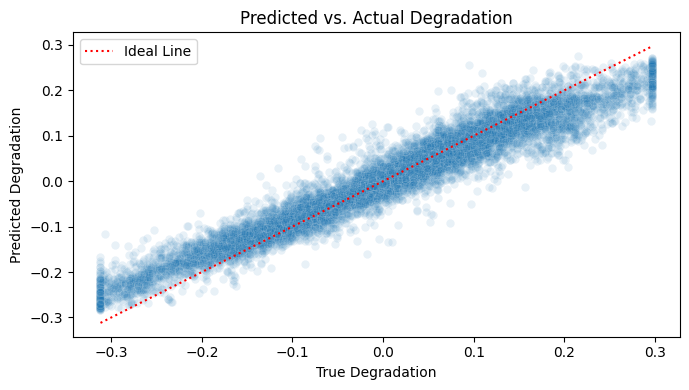

In [33]:

# --- Plot 1: Predicted vs Actual ---
plt.figure(figsize=(7, 4))
sns.scatterplot(x="y_true", y="y_pred", data=results_df, alpha=0.1)
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], ':r', label='Ideal Line')
plt.title("Predicted vs. Actual Degradation")
plt.xlabel("True Degradation")
plt.ylabel("Predicted Degradation")
plt.legend()
plt.grid(False)
plt.tight_layout()
#plt.savefig("predicted_vs_actual.png")
plt.show()
plt.close()

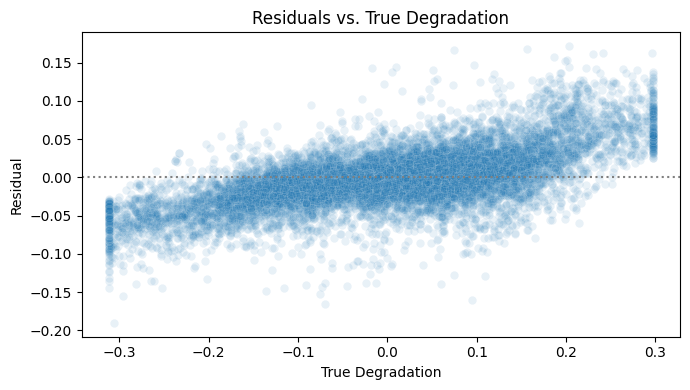

In [34]:
# --- Plot 2: Residuals vs True Degradation ---
plt.figure(figsize=(7, 4))
sns.scatterplot(x="y_true", y="residual", data=results_df, alpha=0.1)
plt.axhline(0, linestyle=':', color='gray')
plt.title("Residuals vs. True Degradation")
plt.xlabel("True Degradation")
plt.ylabel("Residual")
plt.grid(False)
plt.tight_layout()
#plt.savefig("residuals_vs_true.png")
plt.show()
plt.close()

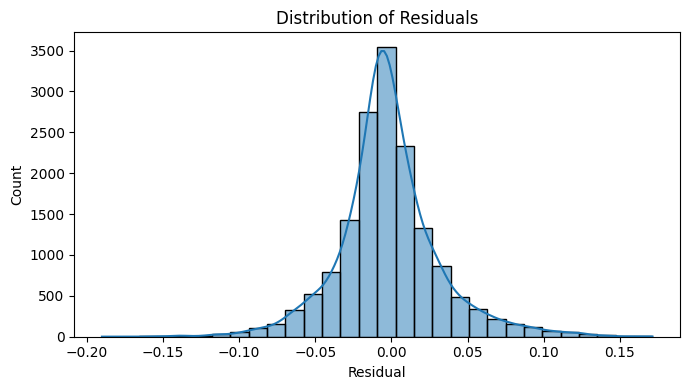

: 

In [ ]:
# --- Plot 3: Histogram of Residuals ---
plt.figure(figsize=(7, 4))
sns.histplot(results_df["residual"], bins=30, kde=True)
plt.title("Distribution of Residuals")
plt.xlabel("Residual")
plt.ylabel("Count")
plt.grid(False)
plt.tight_layout()
#plt.savefig("residuals_histogram.png")
plt.show()
plt.close()

In [21]:
# --- Print Evaluation Metrics ---
r2 = r2_score(y_true, y_pred)
rmse = mean_squared_error(y_true, y_pred, squared=False)
mae = mean_absolute_error(y_true, y_pred)
print(f"R²:   {r2:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")

R²:   0.9219
RMSE: 0.0339
MAE:  0.0241


c:\Users\cisan\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
